# Detección de fraude en tarjetas de crédito

Objetivo: construir un sistema de detección de fraude en tarjetas de crédito usando el dataset etiquetado de construcción.
La idea es intentar que el sistema tenga el mayor AUPR (Área bajo la curva Precision Recall) posible en producción:

from sklearn.metrics import average_precision_score

Se deberá entregar un csv con una única columna con tantas filas como tiene el fichero de producción, y con un score asociado de tal forma que las filas con mayor score sean las que tienen mayor probabilidad de ser fraude.

In [80]:
import sys
COLAB = "google.colab" in sys.modules

In [81]:
import pandas as pd
import numpy as np
from tqdm import tqdm
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score
from sklearn.metrics import average_precision_score

import matplotlib.pyplot as plt
from IPython.display import clear_output

pd.options.display.max_columns = None

# Carga del dataset

In [82]:
COLAB

True

In [83]:
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import is_zipfile

# Jupyter puede arrancar desde la raiz del proyecto o desde notebooks/.
DATA_DIR = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

if COLAB:
    datasets = {
        "credit_card_construction.csv.zip": "1IyihCpU_krumRnPBvMR0ytEfzv_Z2Jg3",
        "credit_card_production.csv.zip": "1N5xRbkchTR7FLskuIEmZPYHklsRVJy_q",
    }
    for filename, file_id in datasets.items():
        destination = DATA_DIR / filename
        if not destination.is_file():
            url = f"https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t"
            temporary = destination.with_suffix(".zip.part")
            urlretrieve(url, temporary)
            if not is_zipfile(temporary):
                temporary.unlink()
                raise ValueError(f"La descarga de {filename} no es un ZIP valido. Revisa el acceso al archivo en Drive.")
            temporary.replace(destination)

print(f"Carpeta de datos: {DATA_DIR.resolve()}")


Carpeta de datos: /content/data


In [84]:
df_const = pd.read_csv(DATA_DIR / "credit_card_construction.csv.zip", compression="zip", low_memory=False)
df_const


,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
0,374.0,-288.0,-150.0,-232.0,-90.0,262.0,-262.0,88.0,-26.0,152.0,212.0,60.0,98.0,-50.0,134.0,178.0,64.0,-322.0,-58.0,20.0,144.00,0
1,436.0,-202.0,-566.0,-652.0,166.0,58.0,-18.0,-0.0,54.0,-54.0,214.0,214.0,-2.0,198.0,248.0,-688.0,108.0,100.0,-34.0,-136.0,10.46,0
2,388.0,-128.0,-56.0,30.0,-114.0,104.0,-210.0,72.0,298.0,2.0,28.0,78.0,-168.0,22.0,82.0,172.0,-218.0,222.0,36.0,-40.0,31.72,0
3,-486.0,4.0,314.0,-80.0,-276.0,-94.0,-34.0,94.0,-252.0,2.0,-198.0,-24.0,116.0,8.0,138.0,-110.0,-86.0,326.0,-358.0,-182.0,134.85,0
4,258.0,-238.0,300.0,-70.0,-374.0,122.0,-350.0,92.0,134.0,94.0,4.0,-40.0,-260.0,-192.0,-382.0,182.0,120.0,-120.0,282.0,-6.0,8.70,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
170879,-398.0,346.0,-222.0,-534.0,322.0,608.0,-84.0,288.0,190.0,204.0,-50.0,4.0,-0.0,-8.0,152.0,196.0,-216.0,2.0,-116.0,156.0,22.24,0
170880,-88.0,212.0,316.0,-6.0,8.0,-180.0,146.0,-22.0,-102.0,-66.0,-54.0,76.0,168.0,-4.0,152.0,32.0,-88.0,-90.0,2.0,32.0,3.87,0
170881,166.0,-530.0,-632.0,42.0,-112.0,-314.0,322.0,-186.0,-264.0,136.0,-182.0,16.0,126.0,152.0,-70.0,-444.0,38.0,136.0,-182.0,178.0,1122.06,0
170882,-304.0,-1258.0,-528.0,266.0,-334.0,392.0,272.0,16.0,150.0,-140.0,174.0,130.0,-52.0,142.0,258.0,62.0,-40.0,-26.0,-296.0,660.0,2657.25,0


In [85]:
100*df_const["Class"].value_counts()/len(df_const)

,count
Class,
0,99.827368
1,0.172632


In [86]:
df_const.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
count,170884.000000,170884.000000,170884.000000,170884.000000,170884.00000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000,170884.000000
mean,0.589499,-0.050923,0.285773,-0.097376,0.28397,0.048828,0.005431,0.217773,-0.020575,-0.082852,0.285469,0.235470,-0.286861,-0.195349,-0.006894,0.196554,-0.288933,-0.278130,0.302778,0.080195,132.118705,0.001726
std,390.920605,330.501997,302.081068,282.572168,270.76069,263.927926,241.111627,238.590168,219.366112,216.787580,204.496836,199.591426,198.824463,191.995036,183.039589,175.058560,169.997903,167.325595,162.131421,152.471380,363.489116,0.041513
min,-11282.000000,-14544.000000,-6594.000000,-1136.000000,-6418.00000,-5232.000000,-8302.000000,-14644.000000,-2686.000000,-4880.000000,-868.000000,-3736.000000,-1158.000000,-3764.000000,-840.000000,-2826.000000,-5032.000000,-1900.000000,-1442.000000,-4730.000000,0.000000,0.000000
25%,-184.000000,-120.000000,-178.000000,-170.000000,-138.00000,-154.000000,-112.000000,-42.000000,-128.000000,-106.000000,-152.000000,-82.000000,-130.000000,-86.000000,-116.000000,-94.000000,-96.000000,-100.000000,-90.000000,-42.000000,8.520000,0.000000
50%,4.000000,14.000000,36.000000,-4.000000,-12.00000,-54.000000,8.000000,4.000000,-10.000000,-18.000000,-6.000000,28.000000,-4.000000,10.000000,10.000000,14.000000,-14.000000,0.000000,0.000000,-12.000000,33.000000,0.000000
75%,264.000000,162.000000,206.000000,150.000000,122.00000,80.000000,114.000000,66.000000,120.000000,92.000000,148.000000,124.000000,132.000000,98.000000,130.000000,104.000000,80.000000,100.000000,92.000000,26.000000,115.445000,0.000000
max,490.000000,4294.000000,1876.000000,3344.000000,6960.00000,4278.000000,6860.000000,4002.000000,3118.000000,4750.000000,2334.000000,1570.000000,874.000000,2106.000000,1166.000000,1412.000000,1850.000000,1008.000000,1114.000000,7884.000000,29484.800000,1.000000


In [87]:
df_prod = pd.read_csv(DATA_DIR / "credit_card_production.csv.zip", compression="zip", low_memory=False)
df_prod

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,X17,X18,X19,X20,Amount,Class
0,234.0,48.0,58.0,106.0,-30.0,-56.0,-22.0,20.0,-38.0,-30.0,360.0,172.0,-32.0,-2.0,136.0,80.0,8.0,-44.0,-52.0,-24.0,1.94,NaN
1,408.0,-126.0,-426.0,-312.0,12.0,-238.0,56.0,-48.0,292.0,-136.0,154.0,118.0,-372.0,204.0,-48.0,-214.0,-4.0,24.0,270.0,-44.0,60.68,NaN
2,-150.0,84.0,580.0,-326.0,-86.0,-100.0,74.0,-32.0,494.0,-418.0,228.0,-348.0,334.0,184.0,30.0,-172.0,142.0,-28.0,-144.0,-18.0,17.77,NaN
3,296.0,-134.0,-388.0,132.0,-12.0,-228.0,114.0,-70.0,44.0,-88.0,304.0,208.0,82.0,-112.0,34.0,78.0,32.0,192.0,-54.0,78.0,416.38,NaN
4,-594.0,-214.0,414.0,308.0,38.0,196.0,-46.0,62.0,70.0,98.0,270.0,32.0,-202.0,-34.0,236.0,-86.0,42.0,28.0,100.0,-222.0,138.00,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113918,392.0,-98.0,-42.0,78.0,-114.0,42.0,-202.0,36.0,490.0,-38.0,310.0,-406.0,134.0,312.0,-176.0,100.0,24.0,160.0,-42.0,-54.0,7.54,NaN
113919,234.0,16.0,-48.0,146.0,36.0,88.0,-64.0,56.0,98.0,-126.0,136.0,62.0,-172.0,-248.0,-108.0,56.0,180.0,88.0,46.0,-22.0,18.46,NaN
113920,-222.0,106.0,430.0,-176.0,74.0,-58.0,152.0,-26.0,34.0,-118.0,-66.0,108.0,110.0,-142.0,-78.0,-88.0,0.0,-270.0,-74.0,18.0,1.34,NaN
113921,-82.0,380.0,-272.0,182.0,322.0,-46.0,238.0,40.0,-206.0,-176.0,-258.0,18.0,202.0,-198.0,-46.0,-82.0,232.0,94.0,162.0,26.0,23.62,NaN


In [88]:
# Matplotlib guarda las figuras como imagenes en el notebook, sin JavaScript.
%matplotlib inline


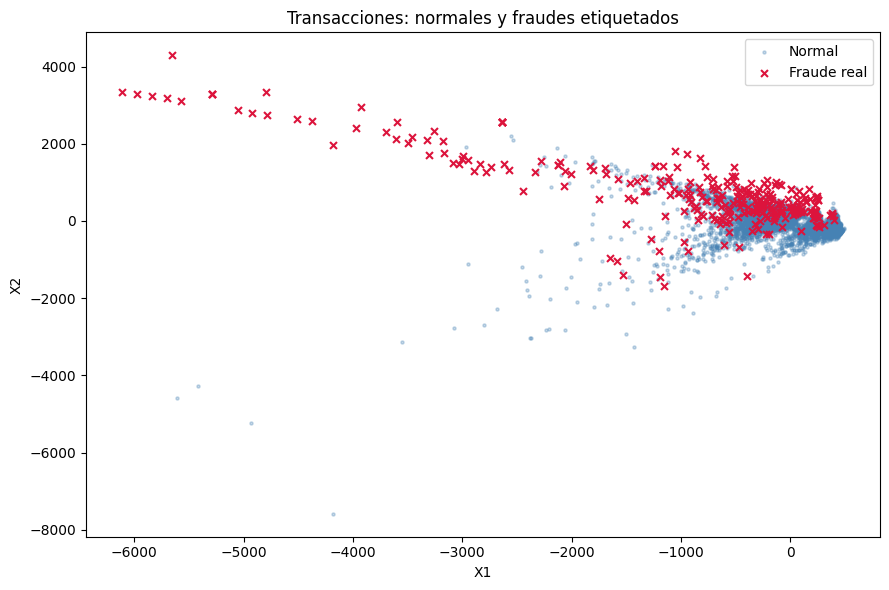

In [89]:
# Muestra reproducible de normales y todos los fraudes para hacerlos visibles.
normales = df_const.loc[df_const["Class"].eq(0)]
fraudes = df_const.loc[df_const["Class"].eq(1)]
muestra = normales.sample(min(10000, len(normales)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(muestra["X1"], muestra["X2"], s=5, alpha=0.3, label="Normal", color="steelblue")
ax.scatter(fraudes["X1"], fraudes["X2"], s=25, marker="x", label="Fraude real", color="crimson")
ax.set(xlabel="X1", ylabel="X2", title="Transacciones: normales y fraudes etiquetados")
ax.legend()
fig.tight_layout()
plt.show()


In [90]:
df_const.std()

,0
X1,390.920605
X2,330.501997
X3,302.081068
X4,282.572168
X5,270.760690
X6,263.927926
X7,241.111627
X8,238.590168
X9,219.366112
X10,216.787580


# Split

In [91]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(df_const, test_size=0.3, random_state=42, stratify=df_const["Class"])

In [92]:
100*df_const["Class"].value_counts()/len(df_const)

,count
Class,
0,99.827368
1,0.172632


In [93]:
100*df_train["Class"].value_counts(normalize = True)

,proportion
Class,
0,99.827785
1,0.172215


In [94]:
100*df_test["Class"].value_counts()/len(df_test)

,count
Class,
0,99.826396
1,0.173604


In [95]:
X_train = df_train.drop("Class", axis=1)
y_train = df_train["Class"]

X_test = df_test.drop("Class", axis=1)
y_test = df_test["Class"]

In [96]:
X_train0 = X_train[y_train==0] # datos ok

In [97]:
X_train0.shape

(119412, 21)

# GMM

In [98]:
# Construyo modelo estadístico de distribución de datos ok:

from sklearn.mixture import GaussianMixture

gm_model = GaussianMixture(n_components=3, random_state=42)
gm_model.fit(X_train0)

GaussianMixture(n_components=3, random_state=42)

In [99]:
gm_model.score_samples(X_train0) # logaritmo de la probabilidad del punto

array([ -99.94290456, -101.48083756, -144.15762968, ..., -106.19134057,
       -166.6163804 , -101.80945005])

In [100]:
scores_train = gm_model.score_samples(X_train)
pd.DataFrame({"score":scores_train, "y":y_train}).sort_values("score")

,score,y
153710,-115660.106434,1
4910,-113801.892030,1
59540,-113798.113066,1
87891,-113798.113066,1
38683,-113798.113066,1
...,...,...
20265,-95.112481,0
29988,-94.927385,0
17408,-94.900715,0
149845,-94.801316,0


## Densidad del GMM: curvas de nivel en PCA 2D

Visualizacion con Matplotlib inspirada en el [ejemplo de scikit-learn](https://scikit-learn.org/stable/auto_examples/mixture/plot_gmm_pdf.html). Las curvas muestran `-log p(PC1, PC2)`: valores altos indican menor densidad en la proyeccion.

Se proyectan las medias y covarianzas del GMM entrenado sobre las transacciones normales. Es la distribucion marginal en estas dos componentes, no el score original con todas las variables. Una transaccion anomala puede quedar superpuesta con normales al reducir dimensiones. Las cruces rojas son fraudes **reales** (`Class = 1`), no predicciones del modelo.

La vista completa incluye el rango de todo test; la ampliacion usa los percentiles 1 y 99 de cada eje (con margen) y deja fuera algunos extremos para apreciar las curvas. Los ejes se mantienen en las unidades de la PCA sin escalar del analisis original.

Las salidas anteriores de Plotly solo contenian HTML con JavaScript cargado desde `cdn.plot.ly`. Un visor que bloquee scripts o esa descarga puede mostrarlas en blanco ([renderizadores de Plotly](https://plotly.com/python/renderers/)). Estas figuras se guardan como imagenes al ejecutar el notebook.


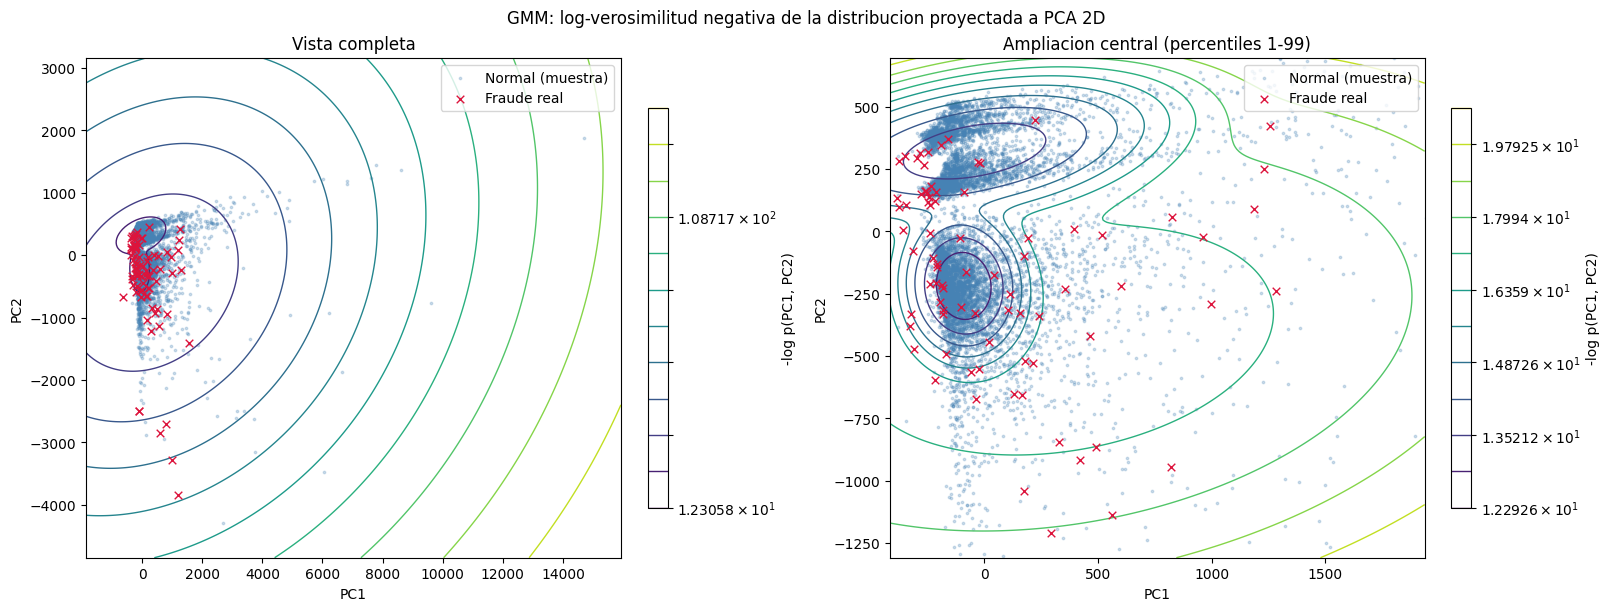

In [101]:
from matplotlib.colors import LogNorm, Normalize
from scipy.special import logsumexp
from scipy.stats import multivariate_normal
from sklearn.decomposition import PCA

# Proyectamos el GMM ya entrenado: cada componente sigue siendo gaussiana.
# No se vuelve a ajustar el modelo ni se modifican scores_train / scores_test.
pca = PCA(n_components=2, random_state=42).fit(X_train0)
Z = pca.transform(X_test)
medias_2d = (gm_model.means_ - pca.mean_) @ pca.components_.T
componentes = pca.components_
covarianzas_2d = np.array([
    componentes @ cov @ componentes.T for cov in gm_model.covariances_
])

def log_densidad_2d(puntos):
    log_componentes = np.column_stack([
        np.log(peso) + multivariate_normal.logpdf(puntos, mean=media, cov=cov)
        for peso, media, cov in zip(gm_model.weights_, medias_2d, covarianzas_2d)
    ])
    return logsumexp(log_componentes, axis=1)

es_fraude = np.asarray(y_test) == 1
indices_normales = np.flatnonzero(~es_fraude)
rng = np.random.default_rng(42)
indices_muestra = rng.choice(indices_normales, min(10000, len(indices_normales)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), layout="constrained")
for ax, titulo, cuantiles in zip(
    axes, ["Vista completa", "Ampliacion central (percentiles 1-99)"], [(0, 1), (0.01, 0.99)]
):
    limites = np.quantile(Z, cuantiles, axis=0)
    margen = np.maximum(limites[1] - limites[0], 1e-6) * 0.08
    inferior, superior = limites[0] - margen, limites[1] + margen
    x = np.linspace(inferior[0], superior[0], 220)
    y = np.linspace(inferior[1], superior[1], 220)
    xx, yy = np.meshgrid(x, y)
    nll = -log_densidad_2d(np.column_stack([xx.ravel(), yy.ravel()])).reshape(xx.shape)

    # LogNorm requiere valores positivos; una densidad puede superar 1.
    vmin, vmax = float(nll.min()), float(nll.max())
    if vmin > 0:
        niveles = np.geomspace(vmin, vmax, 12)
        norma = LogNorm(vmin=vmin, vmax=vmax)
    else:
        niveles = np.linspace(vmin, vmax, 12)
        norma = Normalize(vmin=vmin, vmax=vmax)
    curvas = ax.contour(xx, yy, nll, levels=niveles, norm=norma, cmap="viridis", linewidths=1)
    fig.colorbar(curvas, ax=ax, shrink=0.8, label="-log p(PC1, PC2)")
    ax.scatter(Z[indices_muestra, 0], Z[indices_muestra, 1], s=3, alpha=0.25,
               color="steelblue", label="Normal (muestra)")
    ax.scatter(Z[es_fraude, 0], Z[es_fraude, 1], s=30, marker="x",
               color="crimson", linewidths=1, label="Fraude real", zorder=3)
    ax.set(xlim=(inferior[0], superior[0]), ylim=(inferior[1], superior[1]),
           xlabel="PC1", ylabel="PC2", title=titulo)
    ax.legend(loc="upper right")

fig.suptitle("GMM: log-verosimilitud negativa de la distribucion proyectada a PCA 2D")
plt.show()


# Isolation Forest

In [120]:
from sklearn.ensemble import IsolationForest

In [121]:
if_model = IsolationForest(verbose=1)
if_model.fit(X_train0)

[Parallel(n_jobs=1)]: Done   1 out of   1 | elapsed:    0.4s finished


IsolationForest(verbose=1)

In [125]:
X_train0.shape

(119412, 21)

In [128]:
predictions = if_model.predict(X_test)
data = pd.DataFrame()
data["preds"] = predictions
data["preds"].value_counts()

[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.1s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.3s finished


,count
preds,
1,48834
-1,2432


In [129]:
predictions.shape

(51266,)

In [130]:
from sklearn.metrics import confusion_matrix, classification_report

# Mapeamos -1 a 1 (Fraude) y 1 a 0 (Normal)
y_pred_mapped = np.where(predictions == -1, 1, 0)

# Calculamos la matriz de confusión
cm = confusion_matrix(y_test, y_pred_mapped)
print("Matriz de Confusión:")
print(cm)

# También imprimimos un reporte de clasificación detallado
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred_mapped, target_names=['Normal (0)', 'Fraude (1)']))

Matriz de Confusión:
[[48823  2354]
 [   11    78]]

Reporte de Clasificación:
              precision    recall  f1-score   support

  Normal (0)       1.00      0.95      0.98     51177
  Fraude (1)       0.03      0.88      0.06        89

    accuracy                           0.95     51266
   macro avg       0.52      0.92      0.52     51266
weighted avg       1.00      0.95      0.97     51266



In [131]:
from sklearn.metrics import average_precision_score

# Obtenemos las puntuaciones continuas del Isolation Forest (valores más negativos = más anómalos)
if_scores = if_model.score_samples(X_test)

# Invertimos el signo para que los valores más altos correspondan a mayor probabilidad de anomalía (fraude)
if_scores_inverted = -if_scores

# Calculamos el AUPR (Average Precision Score)
aupr_if = average_precision_score(y_test, if_scores_inverted)

print(f"AUPR (Isolation Forest): {aupr_if:.5f}")

AUPR (Isolation Forest): 0.16107


[Parallel(n_jobs=1)]: Done  49 tasks      | elapsed:    0.2s
[Parallel(n_jobs=1)]: Done 100 out of 100 | elapsed:    0.3s finished


In [132]:
import itertools
from sklearn.metrics import average_precision_score
from sklearn.ensemble import IsolationForest

# 1. Definimos la grilla de hiperparámetros a explorar
param_grid = {
    'n_estimators': [100, 200, 300],      # Número de árboles
    'max_samples': ['auto', 256, 512],    # Muestras por árbol (por defecto auto = min(256, n_samples))
    'max_features': [1.0, 0.8, 0.5]       # Fracción de características (columnas) a usar
}

# 2. Generamos todas las combinaciones posibles
keys, values = zip(*param_grid.items())
combinaciones = [dict(zip(keys, v)) for v in itertools.product(*values)]

mejor_aupr = 0
mejores_params = None

print(f"Probando {len(combinaciones)} combinaciones de hiperparámetros...\n")

# 3. Iteramos sobre cada combinación
for params in combinaciones:
    # Entrenamos el modelo SOLO con los datos normales (X_train0)
    # n_jobs=-1 usa todos los cores disponibles para paralelizar
    modelo = IsolationForest(**params, random_state=42, n_jobs=-1)
    modelo.fit(X_train0)

    # Obtenemos el score de anomalía para X_test e invertimos el signo
    scores_test = -modelo.score_samples(X_test)

    # Calculamos el AUPR
    aupr = average_precision_score(y_test, scores_test)

    print(f"Params: {params} -> AUPR: {aupr:.5f}")

    # Guardamos el mejor modelo
    if aupr > mejor_aupr:
        mejor_aupr = aupr
        mejores_params = params

print("\n" + "="*50)
print(f"Mejor AUPR alcanzado: {mejor_aupr:.5f}")
print(f"Con los parámetros: {mejores_params}")
print("="*50)

Probando 27 combinaciones de hiperparámetros...

Params: {'n_estimators': 100, 'max_samples': 'auto', 'max_features': 1.0} -> AUPR: 0.11933
Params: {'n_estimators': 100, 'max_samples': 'auto', 'max_features': 0.8} -> AUPR: 0.08534
Params: {'n_estimators': 100, 'max_samples': 'auto', 'max_features': 0.5} -> AUPR: 0.18847
Params: {'n_estimators': 100, 'max_samples': 256, 'max_features': 1.0} -> AUPR: 0.11933
Params: {'n_estimators': 100, 'max_samples': 256, 'max_features': 0.8} -> AUPR: 0.08534
Params: {'n_estimators': 100, 'max_samples': 256, 'max_features': 0.5} -> AUPR: 0.18847
Params: {'n_estimators': 100, 'max_samples': 512, 'max_features': 1.0} -> AUPR: 0.14437
Params: {'n_estimators': 100, 'max_samples': 512, 'max_features': 0.8} -> AUPR: 0.16998
Params: {'n_estimators': 100, 'max_samples': 512, 'max_features': 0.5} -> AUPR: 0.19506
Params: {'n_estimators': 200, 'max_samples': 'auto', 'max_features': 1.0} -> AUPR: 0.13355
Params: {'n_estimators': 200, 'max_samples': 'auto', 'max_f